# Calibration LCR

In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
fileRoots = []
for root, dirs, files in os.walk("data/LCR/"):
    for file in files:
        if file.endswith(".csv"):
            fileRoots.append(os.path.join(root, file))
            print(f"Found file: {file}")

measurements = []
names = []
for file in fileRoots:
    temp = np.loadtxt(file, delimiter=",", dtype=str)
    measurements.append(np.array(temp[1:, :], dtype=float))
    names.append(temp[0, :])

measurements = np.array(measurements)
names

Found file: lcvr-calibration-lcvr1-2026-11-03T15:41:39.csv
Found file: lcvr-calibration-lcvr2-2026-11-03T15:51:52.csv
Found file: lcvr-calibration-lcvr3-2026-11-03T15:56:22.csv
Found file: lcvr-calibration-lcvr4-2026-11-03T16:04:25.csv


/tmp/ipykernel_21072/1397888537.py:14: UserWarning: Input line 1 contained no data and will not be counted towards `max_rows=50000`.  This differs from the behaviour in NumPy <=1.22 which counted lines rather than rows.  If desired, the previous behaviour can be achieved by using `itertools.islice`.
Please see the 1.23 release notes for an example on how to do this.  If you wish to ignore this warning, use `warnings.filterwarnings`.  This warning is expected to be removed in the future and is given only once per `loadtxt` call.
  temp = np.loadtxt(file, delimiter=",", dtype=str)


[array(['step', 'voltage_set_v', 'voltage_read_v', 'exposure_ms', 'mean',
        'max', 'mean_r', 'mean_g', 'mean_b'], dtype='<U18'),
 array(['step', 'voltage_set_v', 'voltage_read_v', 'exposure_ms', 'mean',
        'max', 'mean_r', 'mean_g', 'mean_b'], dtype='<U18'),
 array(['step', 'voltage_set_v', 'voltage_read_v', 'exposure_ms', 'mean',
        'max', 'mean_r', 'mean_g', 'mean_b'], dtype='<U18'),
 array(['step', 'voltage_set_v', 'voltage_read_v', 'exposure_ms', 'mean',
        'max', 'mean_r', 'mean_g', 'mean_b'], dtype='<U18')]

Text(0, 0.5, 'Intensities mean_g')

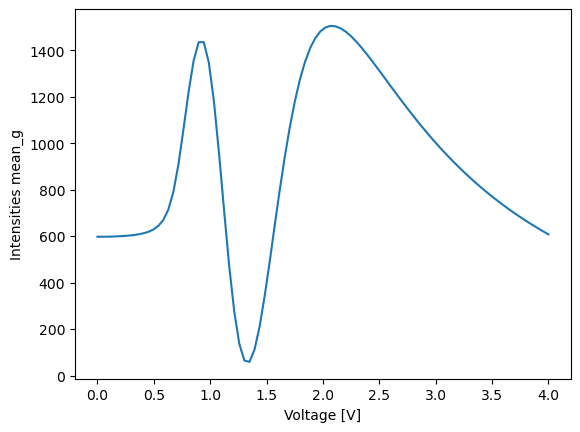

In [4]:
plt.plot(measurements[0,:,2], measurements[0,:,7])
plt.xlabel("Voltage [V]")
plt.ylabel(f"Intensities {names[0][7]}")

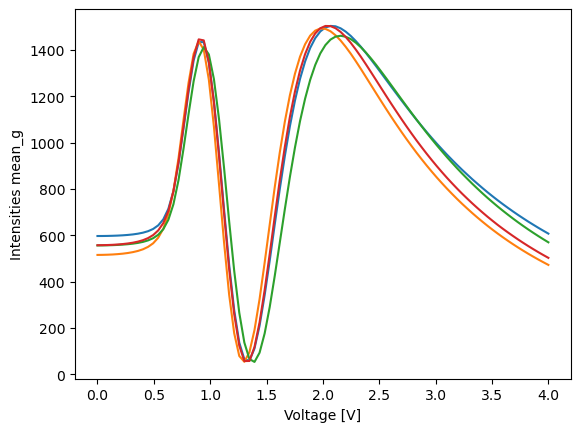

In [5]:
for i in range(len(measurements)):
    plt.plot(measurements[i,:,2], measurements[i,:,7], label=f"Measurement {i+1}")
    plt.xlabel("Voltage [V]")
    plt.ylabel(f"Intensities {names[i][7]}")

In [52]:
from lmfit.models import Model
# 3000, -3.97, 9.97, -3.90, 0.454, 1.35
def intens(x, Intensity=3000, a=-3.97, b=9.97, c=-3.90, d=0.454, e=1.35, f=0.1, g=0.1, h=0.1, i=0.1):
    return 1/4 * (Intensity-Intensity*np.cos(a*x+b*x**2 + c*x**3 + d * x**4 + e *x**5 + f * x**6 + g * x**7 + h * x**8 + i))

# def intens(x, Intensity=1, a=0.1, b=0.1, mu1=0.05, lam1=-0.1, mu2=0.5, lam2=0.1):
#     return 1/4 * (Intensity-Intensity*np.cos(a*x+b*x*np.exp((x-mu1)*lam1+(x-mu2)*lam2)))

def ret(x, a, b, c, d, e):
    return a*np.deg2rad(x)+b*np.deg2rad(x)**2 + c*np.deg2rad(x)**3 + d * np.deg2rad(x)**4 + e

mod = Model(intens)#GaussianModel(prefix = "a")+GaussianModel(prefix = "b")

pars = mod.make_params()
pars


name,value,initial value,min,max,vary
Intensity,3000.00000,None,-inf,inf,True
a,-3.97000000,None,-inf,inf,True
b,9.97000000,None,-inf,inf,True
c,-3.90000000,None,-inf,inf,True
d,0.45400000,None,-inf,inf,True
e,1.35000000,None,-inf,inf,True
f,0.10000000,None,-inf,inf,True
g,0.10000000,None,-inf,inf,True
h,0.10000000,None,-inf,inf,True
i,0.10000000,None,-inf,inf,True


In [53]:
def update_model(fileindex,xName="Spannung [V]", yName="Intensität Grün", yDataErr=0.1, xDataErr=0.1, **params):
    # Setze die Werte der Parameter
    for name, value in params.items():
        pars[name].value = value

    # Berechne Modell mit aktuellen Parametern
    x = measurements[fileindex,:,2]
    x_fit = np.arange(x.min(), x.max(), (x.max() - x.min())/10000)
    y_fit = mod.eval(pars, x=x_fit)

    # Plotten der Daten und des Modells
    plt.figure(figsize=(8, 6))
    plt.errorbar(y = measurements[fileindex,:,7], yerr = yDataErr, x = measurements[fileindex,:,2], xerr = xDataErr, \
        fmt = 'o', markersize = 3.5, alpha = 1, mfc = 'black', c = 'skyblue', zorder = 0, \
        label = r'Werte')
    
    plt.plot(x_fit, y_fit, label="Modell", color='red')
    
    plt.ylabel(yName, fontsize=20)
    plt.xlabel(xName, fontsize=20)
    plt.title('Models')
    result = mod.fit(measurements[fileindex,:,7], pars, x=measurements[fileindex,:,2])
    dynamic_resolution_array = np.arange(min(measurements[fileindex,:,2]),max(measurements[fileindex,:,2]), 0.001*abs(max(measurements[fileindex,:,2])-min(measurements[fileindex,:,2])))
    plt.plot(dynamic_resolution_array, result.eval(x = dynamic_resolution_array), 'b-', label = r'Fit')
    plt.tight_layout()
    plt.legend()
    plt.show()
    print(result.fit_report)
    

In [ ]:
from ipywidgets import interact, FloatText, IntText, fixed, Textarea
param_widgets = {}
for param_name, param in pars.items():
    param_widgets[param_name] = FloatText(value=param.value,
                                            step=0.1,
                                            description=param_name)

# Interaktive Anzeige mit automatisch generierten Slidern
interact(update_model, fileindex=IntText(value=0), **param_widgets)
print()

interactive(children=(IntText(value=0, description='fileindex'), Text(value='Spannung [V]', description='xName…

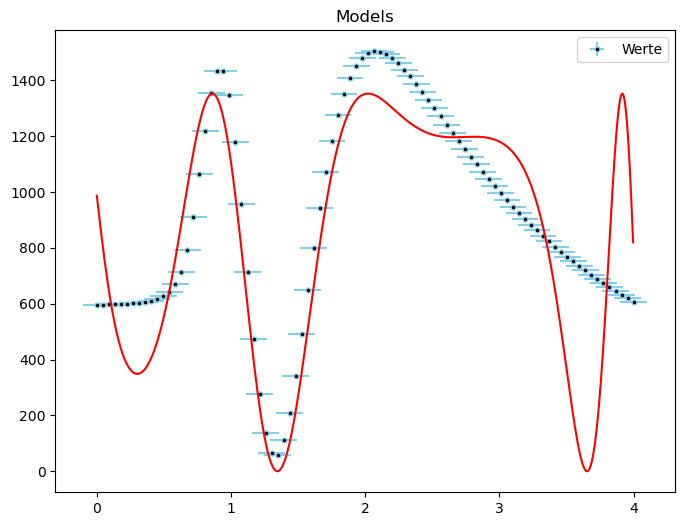

In [20]:

def intens(x, Intensity=3500, a=250, b=0.1, c=0.1, d=0.1, e=0.1):
    return 1/4 * (Intensity-Intensity*np.cos(a*np.deg2rad(x)+b*np.deg2rad(x)**2 + c*np.deg2rad(x)**3 + d * np.deg2rad(x)**4 + e))
#
mod = Model(intens)#GaussianModel(prefix = "a")+GaussianModel(prefix = "b")

pars = mod.make_params()
pars
result = mod.fit(measurements[0,:,7], pars, x=measurements[0,:,2])
dynamic_resolution_array = np.arange(min(measurements[0,:,2]),max(measurements[0,:,2]), 0.001*abs(max(measurements[0,:,2])-min(measurements[0,:,2])))

plt.figure(figsize=(8, 6))
plt.errorbar(y = measurements[0,:,7], yerr = 0.1, x = measurements[0,:,2], xerr = 0.1, \
    fmt = 'o', markersize = 3.5, alpha = 1, mfc = 'black', c = 'skyblue', zorder = 0, \
    label = r'Werte')

#plt.plot(x_fit, y_fit, label="Modell", color='red')
plt.legend()

plt.title('Models')

plt.plot(dynamic_resolution_array, result.eval(x = dynamic_resolution_array), 'r-', label = r'Fit: reduced $\chi^2$ =  ')

plt.show()

In [21]:
result

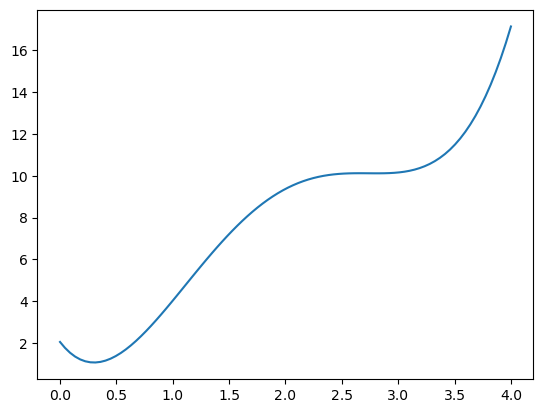

In [23]:
def ret (x, a, b, c, d, e):
    return a*np.deg2rad(x)+b*np.deg2rad(x)**2 + c*np.deg2rad(x)**3 + d * np.deg2rad(x)**4 + e

plt.plot(measurements[0,:,2], ret(measurements[0,:,2], -402.259281, 46645.4564, -1126876.33, 8388224.59,2.04835528))

# Skript

In [ ]:
from MuellerLib import *
from tifffile import imwrite, imread
from tqdm import tqdm

Proben = np.array([np.eye(4), MuellerLinearPolarizer(0), MuellerLinearPolarizer(45), MuellerRetarder(90,0)])
cmw = imread("data/CalData_Example.tif")
A, W, eps, s = ecm_calibrate(cmw, Proben)

BigSRes = imread("data/SRes_Example.tif")
# BigSRes = np.tile(SRes.reshape(256,256,36), (8, 8, 1)) # Nur weil tif datei zu groß
pictureDim1, pictureDim2 = BigSRes.shape[0], BigSRes.shape[1]
Reconst = np.zeros(((pictureDim1, pictureDim2, 16)))
MMD_LD  = np.zeros((pictureDim1, pictureDim2))
MMD_LD_Ori = np.zeros((pictureDim1, pictureDim2))
MMD_LR = np.zeros((pictureDim1, pictureDim2))
MMD_psi = np.zeros((pictureDim1, pictureDim2))

for i in tqdm(range(pictureDim1)):
	Reconst[i,:,:] = reconstMueller(A, BigSRes[i,:,:], W).reshape(-1, 16)
	MMD_LR[i], MMD_psi[i], MMD_LD[i], MMD_LD_Ori[i] = differentialDecompositionFull(Reconst[i,:,:].reshape(-1, 4, 4))

In [ ]:
plt.figure(figsize=(24, 16))
plt.subplot(2, 2, 1)
plt.title("Original Image")
OrigImage = Probe.reshape(256, 256, 4, 4)
OrigImage = OrigImage.transpose(2, 0, 3, 1)
OrigImage = OrigImage.reshape(4*256, 4*256)
plt.imshow(OrigImage, cmap="viridis")
plt.colorbar()

plt.subplot(2, 2, 2)
plt.title("Reconstructed Image")
RecImage = Reconst.reshape(256, 256, 4, 4)
RecImage = RecImage.transpose(2, 0, 3, 1)
RecImage = RecImage.reshape(4*256, 4*256)
plt.imshow(RecImage, cmap="viridis")
plt.colorbar()

plt.subplot(2,2,3)
plt.title("Reconstruction Error")
Error = OrigImage-RecImage
plt.imshow(Error, cmap="viridis")
plt.colorbar()

plt.show()

plt.figure(figsize=(24, 32))
plt.subplot(3, 2, 1)
plt.title("Diattenuation")
plt.imshow(MMD_LD.reshape(256,256), cmap="viridis")
plt.colorbar()

plt.subplot(3, 2, 2)
plt.title("Depolarization")
plt.imshow(MMD_LD_Ori.reshape(256,256), cmap="viridis")
plt.colorbar()

plt.subplot(3,2,3)
plt.title("Linear Retardance")
plt.imshow(MMD_LR.reshape(256,256), cmap="viridis")
plt.colorbar()

# plt.subplot(3,2,4)
# plt.title("Circular Retardance")
# plt.imshow(MMD_CR.reshape(256,256), cmap="viridis")
# plt.colorbar()

plt.subplot(3,2,5)
plt.title("Orientation")
plt.imshow(MMD_psi.reshape(256,256), cmap="viridis")
plt.colorbar()